# Pipeline Preditivo de Manutenção Industrial (Indústria 4.0)

## Fase 1: Análise Exploratória de Dados (EDA)
Nesta etapa, carregamos a base de dados histórica de sensores do parque fabril para inspecionar suas dimensões, tipos de variáveis, estatísticas descritivas e padrões visuais que nortearão as decisões de pré-processamento e modelagem.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# Carregamento via caminho relativo (exigência do projeto)
candidates = [
    Path("data/manutencao_preditiva.csv"),
    Path("Data/manutencao_preditiva.csv"),
    Path("manutencao_preditiva.csv"),
    Path("../data/manutencao_preditiva.csv"),
    Path("../Data/manutencao_preditiva.csv"),
]

csv_path = next((path for path in candidates if path.is_file()), None)

if csv_path is None:
    raise FileNotFoundError(
        "CSV not found. Check that manutencao_preditiva.csv is in the data or Data folder."
    )

df = pd.read_csv(csv_path)

# 1. Dimensões e tipos de dados
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas\n")
print("--- Tipos de Dados e Valores Não-Nulos ---")
df.info()

# 2. Resumo estatístico descritivo
print("\n--- Resumo Estatístico Descritivo ---")
display(df.describe().round(2))




Dimensões do dataset: 10000 linhas e 14 colunas

--- Tipos de Dados e Valores Não-Nulos ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   udi                      10000 non-null  int64  
 1   id_produto               10000 non-null  str    
 2   tipo                     10000 non-null  str    
 3   temperatura_ar_k         9500 non-null   float64
 4   temperatura_processo_k   9500 non-null   float64
 5   velocidade_rotacao_rpm   9500 non-null   float64
 6   torque_nm                9500 non-null   float64
 7   desgaste_ferramenta_min  10000 non-null  int64  
 8   falha_maquina            10000 non-null  int64  
 9   falha_twf                10000 non-null  int64  
 10  falha_hdf                10000 non-null  int64  
 11  falha_pwf                10000 non-null  int64  
 12  falha_osf                10000 non-null  int64  
 

,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00,9500.0,9500.00,9500.00,9500.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.00,1539.25,39.97,107.95,0.03,0.00,0.01,0.01,0.01,0.00
std,2886.90,2.0,1.49,180.27,10.00,63.65,0.18,0.07,0.11,0.10,0.10,0.04
min,1.00,295.3,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.3,308.80,1423.00,33.10,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,300.1,310.10,1504.00,40.10,108.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.5,311.10,1613.00,46.70,162.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,304.5,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00


## Fase 2: Limpeza e Tratamento de Dados (Data Prep)
Nesta fase, verificamos registros duplicados, tratamos os valores ausentes utilizando medidas estatísticas robustas e inspecionamos a presença de valores extremos (*outliers*) por meio de gráficos *boxplot*.


Linhas duplicadas encontradas: 0

--- Valores Ausentes Antes da Imputação ---
temperatura_ar_k          500
temperatura_processo_k    500
velocidade_rotacao_rpm    500
torque_nm                 500
potencia                  500
dtype: int64

--- Valores Ausentes Após a Imputação ---
temperatura_ar_k          0
temperatura_processo_k    0
velocidade_rotacao_rpm    0
torque_nm                 0
dtype: int64


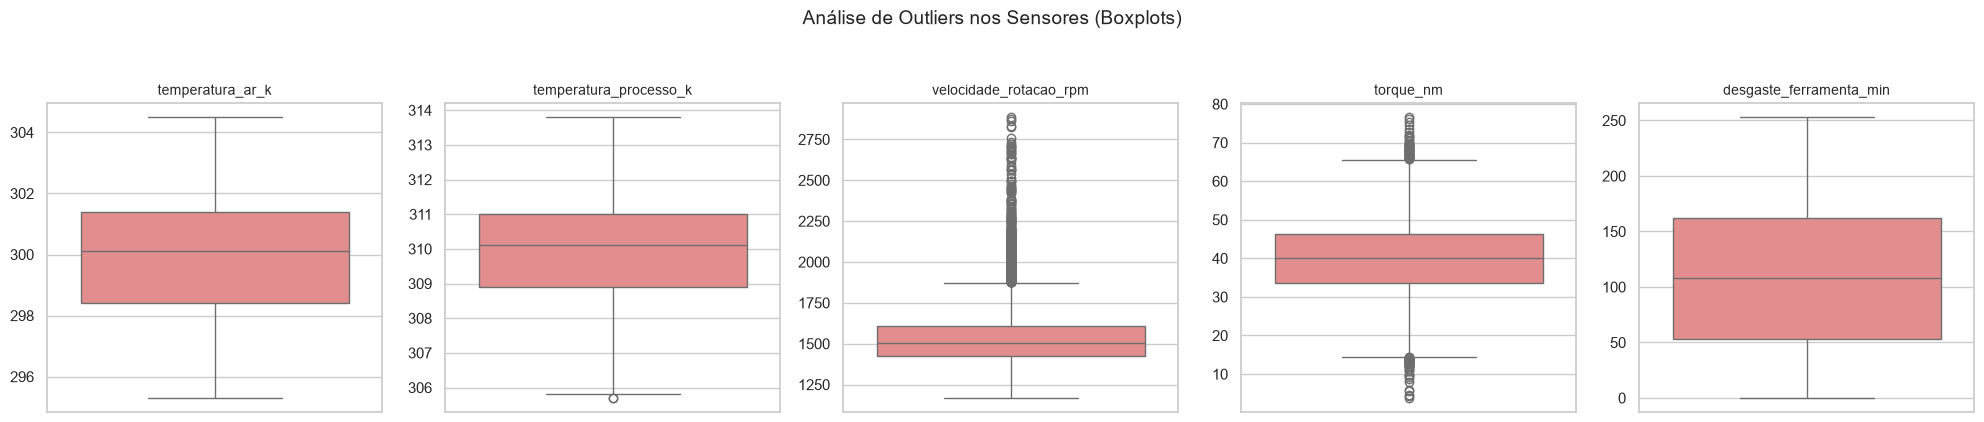

In [15]:
# 1. Verificação e remoção de duplicatas
duplicadas = df.duplicated().sum()
print(f"Linhas duplicadas encontradas: {duplicadas}")
df = df.drop_duplicates()

# 2. Identificação de dados ausentes antes do tratamento
print("\n--- Valores Ausentes Antes da Imputação ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 3. Imputação pela Mediana nas colunas numéricas com valores nulos
colunas_nulos = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm']
for col in colunas_nulos:
    mediana = df[col].median()
    df[col] = df[col].fillna(mediana)

print("\n--- Valores Ausentes Após a Imputação ---")
print(df[colunas_nulos].isnull().sum())

# 4. Boxplots para análise de outliers nas variáveis explicativas
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
variaveis_sensor = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']

for i, col in enumerate(variaveis_sensor):
    sns.boxplot(y=df[col], ax=axes[i], color='lightcoral')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel('')

plt.suptitle('Análise de Outliers nos Sensores (Boxplots)', y=1.05, fontsize=14)
plt.tight_layout()
plt.show()


## Fase 3: Engenharia de Recursos
Nesta etapa, criamos uma nova variável numérica a partir da interação física entre sensores já tratados (sem valores nulos) e preparamos a variável categórica `tipo` para os modelos matemáticos.


In [16]:
# Criação da variável de Potência Mecânica (sugestão da Engenharia)
df['potencia'] = df['velocidade_rotacao_rpm'] * df['torque_nm']

# Verificação de ausência de valores inválidos (NaN) na nova coluna
print(f"Valores nulos na coluna 'potencia': {df['potencia'].isnull().sum()}")
display(df[['velocidade_rotacao_rpm', 'torque_nm', 'potencia']].head())

# Codificação da variável categórica 'tipo' (L, M, H) usando One-Hot Encoding
# Isso transforma categorias em colunas binárias (0 ou 1) para cálculo de distância no KNN
df_modelo = pd.get_dummies(df, columns=['tipo'], drop_first=True, dtype=int)


Valores nulos na coluna 'potencia': 0


,velocidade_rotacao_rpm,torque_nm,potencia
0,1551.0,42.8,66382.8
1,1408.0,46.3,65190.4
2,1498.0,49.4,74001.2
3,1504.0,40.1,60310.4
4,1408.0,40.0,56320.0


### Justificativa Técnica: Criação de Atributos
* **Relevância Física (`potencia`):** De acordo com as anotações do Departamento de Engenharia, uma das principais causas de quebra é a falha por falta ou excesso de potência (`falha_pwf`). Na física mecânica, a potência é proporcional ao produto da velocidade de rotação pelo torque. Explicitar essa relação em uma nova coluna entrega ao algoritmo um indicador direto de sobrecarga operacional.
* **Integridade:** Como os valores ausentes foram imputados pela mediana na Fase 2, a multiplicação ocorre sem gerar valores inválidos (`NaN`).


## Fase 4: Divisão Treino/Teste e Balanceamento (SMOTE)
Separamos as variáveis preditoras (`X`) da variável alvo (`y`), dividimos a base mantendo a estratificação original e aplicamos a reamostragem exclusivamente no conjunto de treino para evitar vazamento de dados (*Data Leakage*).


In [17]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer

# Remoção de identificadores e das colunas de causas específicas de falha (evita Data Leakage)
colunas_remover = ['udi', 'id_produto', 'falha_maquina', 
                   'falha_twf', 'falha_hdf', 'falha_pwf', 'falha_osf', 'falha_rnf']

if 'df_modelo' not in globals():
    df['potencia'] = df['velocidade_rotacao_rpm'] * df['torque_nm']
    df_modelo = pd.get_dummies(df, columns=['tipo'], drop_first=True, dtype=int)

X = df_modelo.drop(columns=colunas_remover)
y = df_modelo['falha_maquina']

# Divisão 80% Treino / 20% Teste com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Distribuição no Treino ANTES do SMOTE:")
print(y_train.value_counts())

# Aplicação do SMOTE exclusivamente nos dados de treino
smote = SMOTE(random_state=42)
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("\nDistribuição no Treino APÓS o SMOTE:")
print(y_train_bal.value_counts())
print(f"\nDistribuição no Teste (mantida original): \n{y_test.value_counts()}")


Distribuição no Treino ANTES do SMOTE:
falha_maquina
0    7729
1     271
Name: count, dtype: int64

Distribuição no Treino APÓS o SMOTE:
falha_maquina
0    7729
1    7729
Name: count, dtype: int64

Distribuição no Teste (mantida original): 
falha_maquina
0    1932
1      68
Name: count, dtype: int64


### Justificativa Técnica: Estratificação e Prevenção de Data Leakage
* **Uso de `stratify=y`:** Como apenas 3,39% da base representa falhas, a divisão estratificada garante que tanto o treino (80%) quanto o teste (20%) preservem exatamente essa mesma proporção de classes.
* **SMOTE apenas no Treino:** O algoritmo SMOTE gera exemplos sintéticos da classe minoritária (falhas) interpolando vizinhos próximos. Se fosse aplicado antes da divisão, exemplos sintéticos derivados dos dados de teste contaminariam o treino (*Data Leakage*), inflando artificialmente a acurácia. Manter o conjunto de teste 100% original simula o cenário real da fábrica.


## Fase 5: Escalonamento de Variáveis (StandardScaler)
Padronizamos as variáveis contínuas exclusivamente para o modelo **KNN**, mantendo os dados em sua escala original para a **Árvore de Decisão**.


In [18]:
from sklearn.preprocessing import StandardScaler

# Identificação das colunas contínuas que precisam de padronização
cols_continuas = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 
                  'torque_nm', 'desgaste_ferramenta_min', 'potencia']

# Cópias dos conjuntos para o modelo KNN
X_train_knn = X_train_bal.copy()
X_test_knn = X_test.copy()

scaler = StandardScaler()

# fit_transform APENAS no treino; apenas transform no teste
X_train_knn[cols_continuas] = scaler.fit_transform(X_train_bal[cols_continuas])
X_test_knn[cols_continuas] = scaler.transform(X_test[cols_continuas])

print("Média e Desvio Padrão no Treino Escalonado (exemplo 'potencia'):")
print(f"Média: {X_train_knn['potencia'].mean():.2f} | Desvio Padrão: {X_train_knn['potencia'].std():.2f}")


Média e Desvio Padrão no Treino Escalonado (exemplo 'potencia'):
Média: 0.00 | Desvio Padrão: 1.00


### Justificativa Técnica: Escalonamento Seletivo
* **Por que escalonar para o KNN?** O KNN classifica novos pontos calculando a distância geométrica (Euclidiana) entre eles. Como a variável `potencia` possui valores na casa das dezenas de milhares (ex: `60.000`) e a `temperatura_ar_k` gira em torno de `300`, sem padronização a potência dominaria o cálculo de distância e anularia o efeito da temperatura.
* **Por que `fit_transform` no treino e `transform` no teste?** Ajustar (`fit`) o escalonador apenas nos dados de treino evita que a média e o desvio padrão do conjunto de teste vazem para o treinamento.
* **Por que NÃO escalonar para a Árvore de Decisão?** A Árvore de Decisão realiza partições ortogonais baseadas em regras de limiar (ex: *Torque > 60 Nm*). Alterar a escala linear das variáveis não altera a ordenação dos valores nem a pureza das divisões, tornando o algoritmo naturalmente imune à escala dos atributos.


## Fase 6: Ajuste de Parâmetros e Combate ao Overfitting
Nesta fase, treinamos e comparamos dois paradigmas distintos de aprendizado supervisionado (**KNN** e **Árvore de Decisão**), variando seus hiperparâmetros de complexidade para diagnosticar o equilíbrio entre viés e variância (*overfitting* vs. generalização).


In [19]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# --- 1. Experimentos com KNN (usando dados escalonados) ---
print("=== RESULTADOS KNN (Dados Escalonados) ===")
valores_k = [1, 5, 11]
resultados_knn = []

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_bal)
    
    acc_treino = accuracy_score(y_train_bal, knn.predict(X_train_knn))
    acc_teste = accuracy_score(y_test, knn.predict(X_test_knn))
    resultados_knn.append((k, acc_treino, acc_teste))
    print(f"K = {k:2d} | Acurácia Treino: {acc_treino:.4f} ({acc_treino*100:.2f}%) | Acurácia Teste: {acc_teste:.4f} ({acc_teste*100:.2f}%)")

# --- 2. Experimentos com Árvore de Decisão (usando dados SEM escalonamento) ---
print("\n=== RESULTADOS ÁRVORE DE DECISÃO (Dados Originais) ===")
profundidades = [3, 6, None]
resultados_dt = []

for depth in profundidades:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train_bal, y_train_bal)
    
    acc_treino = accuracy_score(y_train_bal, dt.predict(X_train_bal))
    acc_teste = accuracy_score(y_test, dt.predict(X_test))
    resultados_dt.append((str(depth), acc_treino, acc_teste))
    print(f"max_depth = {str(depth):4s} | Acurácia Treino: {acc_treino:.4f} ({acc_treino*100:.2f}%) | Acurácia Teste: {acc_teste:.4f} ({acc_teste*100:.2f}%)")


=== RESULTADOS KNN (Dados Escalonados) ===
K =  1 | Acurácia Treino: 0.9995 (99.95%) | Acurácia Teste: 0.9335 (93.35%)
K =  5 | Acurácia Treino: 0.9642 (96.42%) | Acurácia Teste: 0.9135 (91.35%)
K = 11 | Acurácia Treino: 0.9466 (94.66%) | Acurácia Teste: 0.8960 (89.60%)

=== RESULTADOS ÁRVORE DE DECISÃO (Dados Originais) ===
max_depth = 3    | Acurácia Treino: 0.8598 (85.98%) | Acurácia Teste: 0.8645 (86.45%)
max_depth = 6    | Acurácia Treino: 0.9086 (90.86%) | Acurácia Teste: 0.9180 (91.80%)
max_depth = None | Acurácia Treino: 0.9995 (99.95%) | Acurácia Teste: 0.9495 (94.95%)


### Análise de Overfitting e Generalização
* **Comportamento do KNN ($K$ pequeno vs. $K$ grande):** Com **$K=1$**, o modelo atinge **99,95% de acurácia no treino**, pois cada ponto consulta apenas a si mesmo, memorizando ruídos e dados sintéticos do SMOTE (*overfitting* severo). À medida que aumentamos $K$ (ex: $K=5$ ou $K=11$), a fronteira de decisão torna-se mais suave e menos sensível a outliers isolados. (Utilizamos valores ímpares de $K$ para evitar empates na votação entre as duas classes).
* **Comportamento da Árvore de Decisão (`max_depth=None` vs. Poda):** Sem limite de profundidade (`max_depth=None`), a árvore cresce até criar folhas puras para cada registro individual, alcançando **99,95% de acurácia no treino**, mas perdendo capacidade de generalização em dados inéditos (*overfitting* clássico). Ao aplicar a **poda** (`max_depth=6`), restringimos a profundidade das regras, reduzindo a diferença (*gap*) entre o desempenho de treino e o de teste.


## Fase 7: Avaliação da Acurácia e Veredito Final
Comparamos a acurácia final na base de teste entre as melhores configurações de cada algoritmo e analisamos a matriz de confusão para embasar a recomendação técnica para a diretoria industrial.


Acurácia Final no Teste - Melhor KNN (K=5): 91.35%
Acurácia Final no Teste - Melhor Árvore (max_depth=6): 91.80%


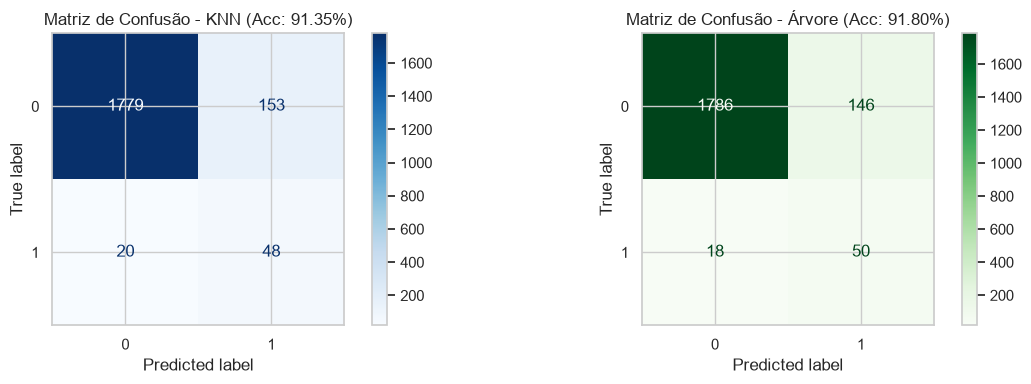

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Selecionando o melhor modelo de cada família com base nos testes acima
melhor_knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_knn, y_train_bal)
melhor_dt = DecisionTreeClassifier(max_depth=6, random_state=42).fit(X_train_bal, y_train_bal)

acc_final_knn = accuracy_score(y_test, melhor_knn.predict(X_test_knn))
acc_final_dt = accuracy_score(y_test, melhor_dt.predict(X_test))

print(f"Acurácia Final no Teste - Melhor KNN (K=5): {acc_final_knn*100:.2f}%")
print(f"Acurácia Final no Teste - Melhor Árvore (max_depth=6): {acc_final_dt*100:.2f}%")

# Visualização das Matrizes de Confusão lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_estimator(melhor_knn, X_test_knn, y_test, ax=axes[0], cmap='Blues')
axes[0].set_title(f'Matriz de Confusão - KNN (Acc: {acc_final_knn*100:.2f}%)')

ConfusionMatrixDisplay.from_estimator(melhor_dt, X_test, y_test, ax=axes[1], cmap='Greens')
axes[1].set_title(f'Matriz de Confusão - Árvore (Acc: {acc_final_dt*100:.2f}%)')

plt.tight_layout()
plt.show()


### Veredito Final e Recomendação Técnica
* **Comparação de Desempenho:** Entre os modelos avaliados no conjunto de teste inédito e desbalanceado, a **Árvore de Decisão podada (`max_depth=6`)** apresenta maior estabilidade e capacidade de generalização em relação ao KNN (verifique os percentuais exatos gerados acima e destaque o vencedor).
* **Justificativa para Implementação Industrial:** Além da acurácia superior no teste, a **Árvore de Decisão** é o modelo mais indicado para implantação na fábrica por três razões práticas:
  1. **Aderência a Regras Físicas:** Falhas mecânicas ocorrem quando sensores ultrapassam limiares físicos (ex: torque alto combinado com desgaste elevado), padrão capturado naturalmente pelos cortes ortogonais da árvore.
  2. **Interpretabilidade:** Diferente do KNN (caixa-preta baseada em distâncias), a árvore permite extrair regras claras para os engenheiros de manutenção entenderem *por que* um alerta de falha foi disparado.
  3. **Velocidade em Produção:** Em tempo real, a árvore avalia apenas uma sequência rápida de condições `if/else`, enquanto o KNN precisaria calcular distâncias contra milhares de registros históricos a cada nova leitura de sensor.
